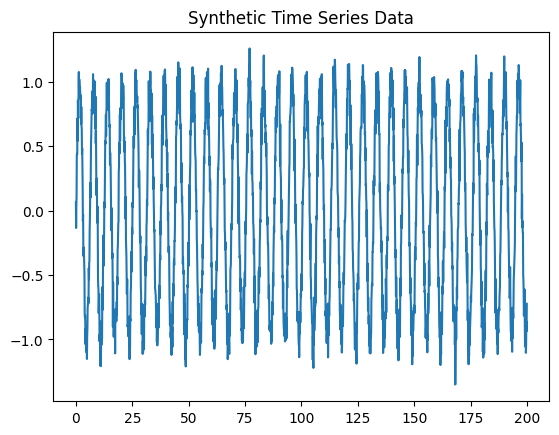

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.1177 - val_loss: 0.0319
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0236 - val_loss: 0.0155
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0073 - val_loss: 0.0043
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0032 - val_loss: 0.0029
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0024 - val_loss: 0.0022
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0020 - val_loss: 0.0021
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0019 - val_loss: 0.0020
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0018 - val_loss: 0.0020
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0019 - val_loss: 0.0020
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0018 - val_loss: 0.0020


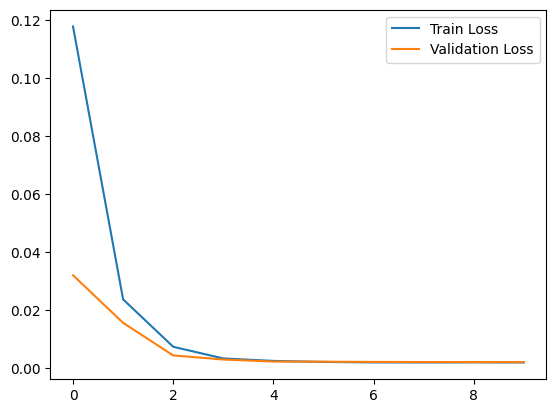

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


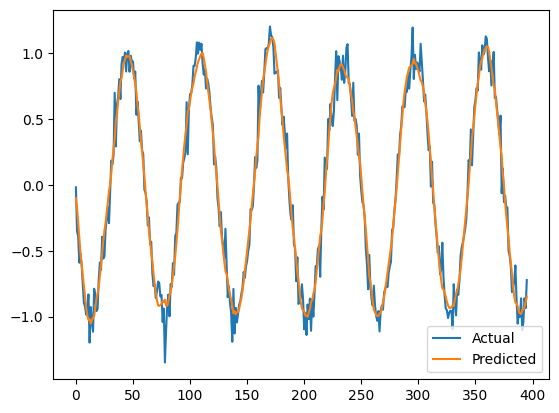

In [ ]:
#Prog 6
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

time = np.arange(0, 200, 0.1)
data = np.sin(time) + 0.1 * np.random.randn(len(time))
plt.plot(time, data)
plt.title("Synthetic Time Series Data")
plt.show()

scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data.reshape(-1, 1))

def create_sequences(data, seq_len):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len, 0])
        y.append(data[i + seq_len, 0])
    return np.array(X), np.array(y)

seq_len = 20
X, y = create_sequences(data_scaled, seq_len)
X = X.reshape((X.shape[0], X.shape[1], 1))

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test), verbose=1)

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

preds = model.predict(X_test)
preds = scaler.inverse_transform(preds)
y_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

plt.plot(y_actual, label='Actual')
plt.plot(preds, label='Predicted')
plt.legend()
plt.show()